In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('student.csv')
df.head()

,student_ID,Age,Gender,StudyHours,Attendence,Marks,Result
0,1,18,Female,2.5,75.0,55.0,Pass
1,2,19,Male,4.0,82.0,68.0,Pass
2,3,18,Female,NaN,68.0,61.0,Pass
3,4,20,Male,6.0,91.0,85.0,Pass
4,5,19,Female,5.0,88.0,78.0,Pass


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   student_ID  10 non-null     int64  
 1   Age         10 non-null     int64  
 2   Gender      10 non-null     object 
 3   StudyHours  9 non-null      float64
 4   Attendence  9 non-null      float64
 5   Marks       9 non-null      float64
 6   Result      10 non-null     object 
dtypes: float64(3), int64(2), object(2)
memory usage: 692.0+ bytes


In [4]:
df.fillna(df.mean(numeric_only=True), inplace=True)
print(df.isnull().sum())

student_ID    0
Age           0
Gender        0
StudyHours    0
Attendence    0
Marks         0
Result        0
dtype: int64


In [5]:
df

,student_ID,Age,Gender,StudyHours,Attendence,Marks,Result
0,1,18,Female,2.5,75.000000,55.000000,Pass
1,2,19,Male,4.0,82.000000,68.000000,Pass
2,3,18,Female,4.0,68.000000,61.000000,Pass
3,4,20,Male,6.0,91.000000,85.000000,Pass
4,5,19,Female,5.0,88.000000,78.000000,Pass
5,6,18,Male,1.5,60.000000,45.000000,Fail
6,7,21,Female,7.0,75.666667,92.000000,Pass
7,8,20,Male,4.5,80.000000,72.000000,Pass
8,9,19,Female,3.5,72.000000,64.000000,Pass
9,10,18,Male,2.0,65.000000,68.888889,Fail


In [6]:
X = df[["Age","StudyHours","Attendence","Marks"]]
y = df["Result"]

In [7]:
encoder = LabelEncoder()
y = encoder.fit_transform(y)

In [8]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [9]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8
Testing samples: 2


In [10]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)

In [11]:
y_pred = model.predict(X_test)


In [12]:
print("Actual:", y_test)
print("Predicted:", y_pred)

Actual: [1 1]
Predicted: [1 1]


In [13]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 1.0


In [14]:
precsion = precision_score(y_test, y_pred,zero_division=0)
print("Precision:", precsion)

Precision: 1.0


In [15]:
recall = recall_score(y_test, y_pred,zero_division=0)
print("Recall:", recall)

Recall: 1.0


In [16]:
f1 = f1_score(y_test, y_pred,zero_division=0)
print("F1-score:", f1)

F1-score: 1.0


In [17]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[2]]


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


ValueError: The number of FixedLocator locations (1), usually from a call to set_ticks, does not match the number of labels (2).

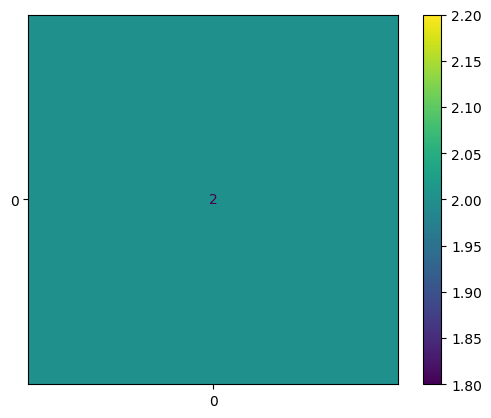

In [19]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=encoder.classes_)
disp.plot()
plt.title("Confusion Matrix")
plt.show()

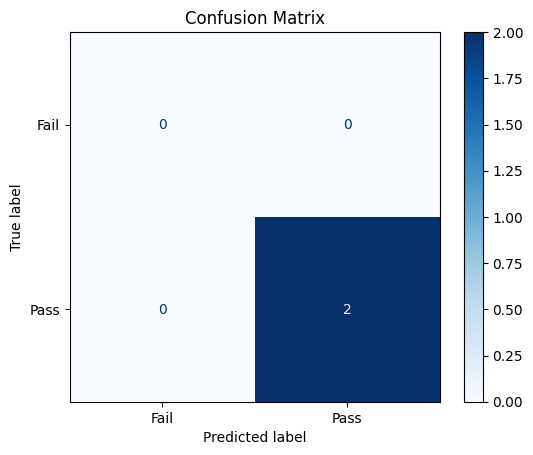

In [22]:
cm = confusion_matrix(
    y_test, y_pred,
    labels=range(len(encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()